# **MÓDULO 33 - Projeto Final de Modelos Avançados**
## Segmentação de Clientes com K-Means

**Autor:** Renan Toyoyama — Profissão Cientista de Dados

**Objetivo do Projeto:** aplicar os conceitos de modelagem avançada para realizar uma **segmentação de clientes** utilizando o algoritmo de clustering **K-Means**, passando por exploração de dados, pré-processamento, implementação e avaliação do modelo.

**Dataset:** informações de 200 clientes de um shopping:

| Coluna | Descrição |
|---|---|
| `CustomerID` | Identificador único do cliente |
| `Gender` | Gênero do cliente |
| `Age` | Idade do cliente |
| `Annual Income (k$)` | Renda anual em milhares de dólares |
| `Spending Score (1-100)` | Pontuação atribuída pelo shopping com base no comportamento e padrão de gastos |

**Roteiro**
1. Exploração de Dados
2. Tratamento de Dados
3. Implementação do K-Means
4. Avaliação e Interpretação dos Resultados
5. Aplicações Práticas e Conclusão

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (
    calinski_harabasz_score,
    davies_bouldin_score,
    silhouette_samples,
    silhouette_score,
)
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 100

RANDOM_STATE = 42
DATA_PATH = Path("../data/Mall_Customers.csv")
FIG_DIR = Path("../reports/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)


def salvar(fig, nome):
    """Salva a figura em reports/figures para uso no README."""
    fig.savefig(FIG_DIR / f"{nome}.png", bbox_inches="tight", dpi=120)

---
# 1. Exploração de Dados

Objetivo: entender as características das variáveis, a distribuição dos dados e verificar valores ausentes, duplicados ou inconsistências.

In [2]:
df_raw = pd.read_csv(DATA_PATH)
print(f"Formato: {df_raw.shape[0]} linhas x {df_raw.shape[1]} colunas")
df_raw.head()

Formato: 200 linhas x 5 colunas


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [3]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   CustomerID              200 non-null    int64
 1   Gender                  200 non-null    str  
 2   Age                     200 non-null    int64
 3   Annual Income (k$)      200 non-null    int64
 4   Spending Score (1-100)  200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 7.9 KB


### 1.1 Qualidade dos dados: ausentes, duplicados e inconsistências

In [4]:
qualidade = pd.DataFrame({
    "tipo": df_raw.dtypes,
    "nulos": df_raw.isna().sum(),
    "valores_unicos": df_raw.nunique(),
})
print(f"Linhas duplicadas: {df_raw.duplicated().sum()}")
print(f"CustomerID duplicados: {df_raw['CustomerID'].duplicated().sum()}")
print(f"Categorias de Gender: {df_raw['Gender'].unique().tolist()}")
qualidade

Linhas duplicadas: 0
CustomerID duplicados: 0
Categorias de Gender: ['Male', 'Female']


,tipo,nulos,valores_unicos
CustomerID,int64,0,200
Gender,str,0,2
Age,int64,0,51
Annual Income (k$),int64,0,64
Spending Score (1-100),int64,0,84


In [5]:
# Checagem de faixas válidas (inconsistências de domínio)
checks = {
    "Idade fora de [0, 120]": (~df_raw["Age"].between(0, 120)).sum(),
    "Renda negativa": (df_raw["Annual Income (k$)"] < 0).sum(),
    "Spending Score fora de [1, 100]": (~df_raw["Spending Score (1-100)"].between(1, 100)).sum(),
}
pd.Series(checks, name="ocorrências")

Idade fora de [0, 120]             0
Renda negativa                     0
Spending Score fora de [1, 100]    0
Name: ocorrências, dtype: int64

> 💡 **Insights**
> - Base **limpa**: 200 registros, sem valores nulos, sem duplicados e sem valores fora do domínio esperado.
> - `CustomerID` é único por linha → é apenas um identificador e **não carrega informação** de comportamento.
> - `Gender` é a única variável categórica (2 categorias); as demais são numéricas inteiras.
> - Não será necessário imputar ou remover registros — o foco do tratamento será **escala** e **seleção de variáveis**.

### 1.2 Estatísticas descritivas

In [6]:
df_raw.drop(columns="CustomerID").describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Age,200.0,38.85,13.97,18.0,28.75,36.0,49.0,70.0
Annual Income (k$),200.0,60.56,26.26,15.0,41.50,61.5,78.0,137.0
Spending Score (1-100),200.0,50.20,25.82,1.0,34.75,50.0,73.0,99.0


> 💡 **Insights**
> - **Idade**: 18 a 70 anos, média ~39 — público majoritariamente adulto jovem/meia-idade.
> - **Renda anual**: 15 a 137 k$, média ~61 k$ — grande amplitude, indica perfis econômicos bem distintos.
> - **Spending Score**: cobre praticamente toda a escala (1 a 99) com média ~50 — há clientes muito econômicos e muito gastadores.
> - As variáveis estão em **escalas diferentes** (idade em dezenas, renda até 137) → será necessário padronizar antes do K-Means, que é baseado em distância.

### 1.3 Distribuição das variáveis numéricas

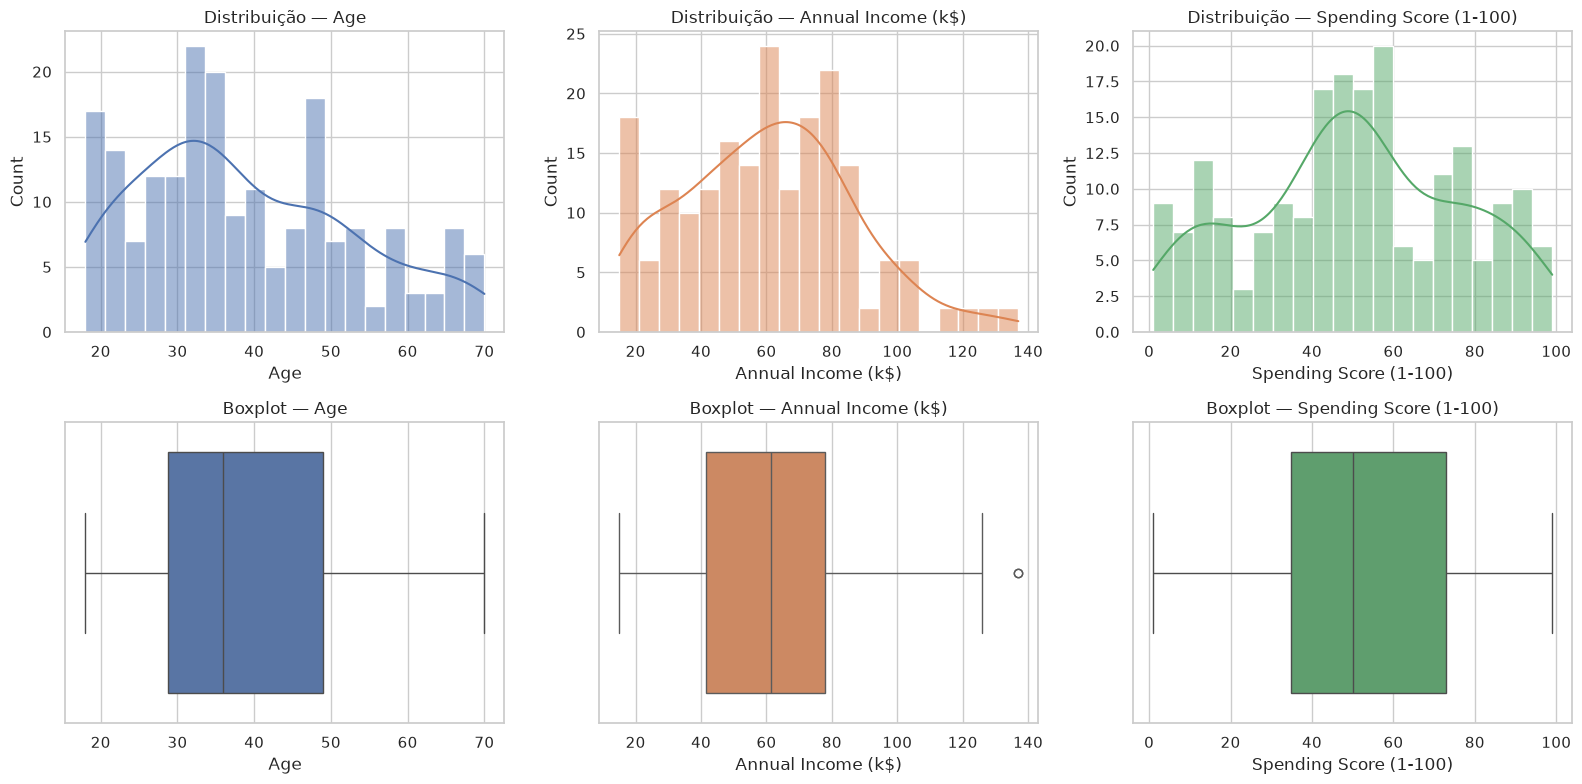

,assimetria
Age,0.49
Annual Income (k$),0.32
Spending Score (1-100),-0.05


In [7]:
num_cols = ["Age", "Annual Income (k$)", "Spending Score (1-100)"]

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for i, col in enumerate(num_cols):
    sns.histplot(df_raw[col], kde=True, bins=20, ax=axes[0, i], color=f"C{i}")
    axes[0, i].set_title(f"Distribuição — {col}")
    sns.boxplot(x=df_raw[col], ax=axes[1, i], color=f"C{i}")
    axes[1, i].set_title(f"Boxplot — {col}")
plt.tight_layout()
salvar(fig, "01_distribuicoes")
plt.show()

df_raw[num_cols].skew().round(2).rename("assimetria").to_frame()

In [8]:
# Outliers pelo critério do IQR (1,5 x intervalo interquartil)
def outliers_iqr(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return s[(s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)]

for col in num_cols:
    out = outliers_iqr(df_raw[col])
    print(f"{col}: {len(out)} outlier(s) {out.tolist()}")

Age: 0 outlier(s) []
Annual Income (k$): 2 outlier(s) [137, 137]
Spending Score (1-100): 0 outlier(s) []


> 💡 **Insights**
> - **Idade** tem leve assimetria à direita (mais clientes entre 20 e 50 anos).
> - **Renda** também é levemente assimétrica à direita, com **2 outliers** (137 k$) — valores plausíveis (clientes de alta renda), não erros. Serão **mantidos**, pois representam um perfil real e são poucos.
> - **Spending Score** é praticamente simétrico, sem outliers.
> - Nenhuma variável exige transformação logarítmica; a **padronização** é suficiente.

### 1.4 Variável categórica: Gênero

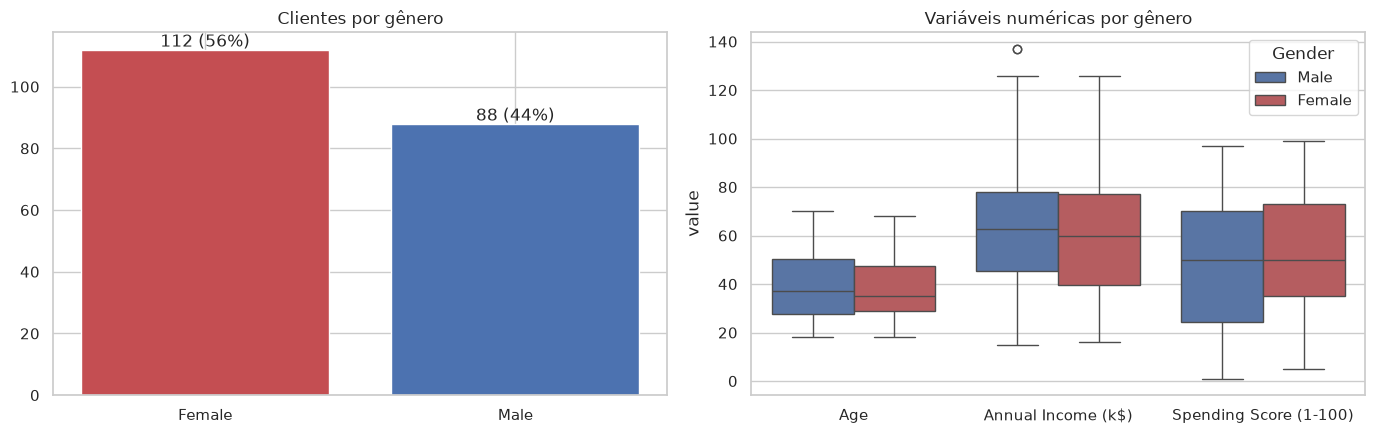

,Age,Annual Income (k$),Spending Score (1-100)
Gender,,,
Female,38.1,59.2,51.5
Male,39.8,62.2,48.5


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
contagem = df_raw["Gender"].value_counts()
axes[0].bar(contagem.index, contagem.values, color=["C3", "C0"])
for i, v in enumerate(contagem.values):
    axes[0].text(i, v + 1, f"{v} ({v / len(df_raw):.0%})", ha="center")
axes[0].set_title("Clientes por gênero")

df_melt = df_raw.melt(id_vars="Gender", value_vars=num_cols)
sns.boxplot(data=df_melt, x="variable", y="value", hue="Gender", ax=axes[1], palette=["C0", "C3"])
axes[1].set_title("Variáveis numéricas por gênero")
axes[1].set_xlabel("")
plt.tight_layout()
plt.show()

df_raw.groupby("Gender")[num_cols].mean().round(1)

> 💡 **Insights**
> - Há leve predominância **feminina** (56% mulheres x 44% homens).
> - As médias de idade, renda e score são **muito parecidas** entre os gêneros (diferenças de 1 a 3 pontos).
> - Gênero, portanto, **não parece discriminar** o comportamento de consumo — forte indício de que não deve ser variável de entrada do clustering (será usado apenas para descrever os clusters).

### 1.5 Relação entre variáveis

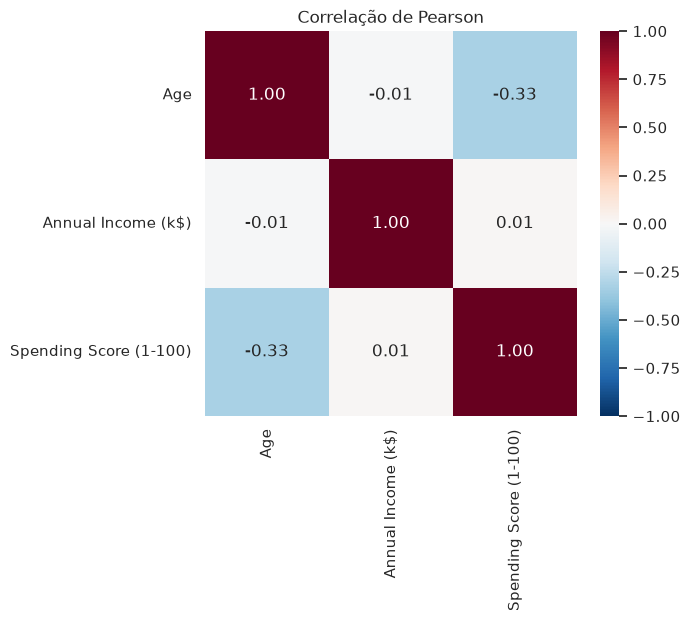

In [10]:
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(df_raw[num_cols].corr(), annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=ax)
ax.set_title("Correlação de Pearson")
plt.show()

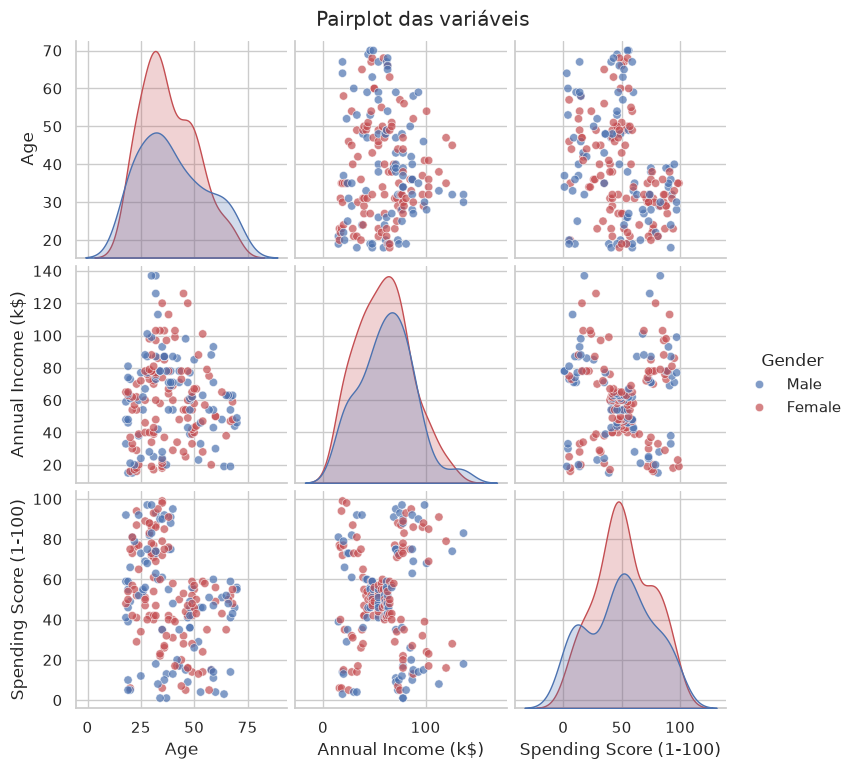

In [11]:
g = sns.pairplot(df_raw.drop(columns="CustomerID"), hue="Gender", diag_kind="kde",
                 palette=["C0", "C3"], plot_kws={"alpha": 0.7})
g.figure.suptitle("Pairplot das variáveis", y=1.02)
salvar(g.figure, "02_pairplot")
plt.show()

> 💡 **Insights**
> - **Renda x Spending Score** têm correlação ~0 linear, mas o gráfico de dispersão revela **5 grupos visualmente separados** (formato de "X" com um centro) — exatamente o tipo de estrutura que o K-Means captura bem.
> - **Idade x Spending Score** têm correlação negativa moderada (-0,33): clientes mais jovens tendem a gastar mais; acima de ~40 anos, scores altos são raros.
> - **Idade x Renda** não têm relação (≈0).
> - A correlação baixa entre as variáveis significa que cada uma traz **informação complementar**, sem redundância.

---
# 2. Tratamento de Dados

| Etapa | Decisão | Justificativa |
|---|---|---|
| Renomear colunas | Nomes curtos em português | Facilita leitura e manipulação |
| `CustomerID` | **Removido** das features | É um identificador sequencial; usá-lo criaria "distância" artificial entre clientes |
| `Gender` | **Não usado** no clustering, mas mantido para perfilar | K-Means usa distância euclidiana; uma variável binária cria apenas 2 "planos" e tende a dividir os clusters por gênero, que a EDA mostrou não diferenciar o consumo |
| Outliers de renda | **Mantidos** | São apenas 2, plausíveis, e representam clientes de alta renda reais |
| Escala | **StandardScaler** (média 0, desvio 1) | K-Means é sensível à escala: sem padronização, a variável de maior amplitude dominaria a distância |
| Variáveis derivadas | `faixa_etaria` (só para análise) | Ajuda a interpretar os clusters; não entra no modelo |

In [12]:
df = df_raw.rename(columns={
    "CustomerID": "id_cliente",
    "Gender": "genero",
    "Age": "idade",
    "Annual Income (k$)": "renda_anual",
    "Spending Score (1-100)": "score_gasto",
})
df["genero"] = df["genero"].map({"Male": "Masculino", "Female": "Feminino"})
df["faixa_etaria"] = pd.cut(df["idade"], bins=[17, 25, 35, 45, 55, 70],
                            labels=["18-25", "26-35", "36-45", "46-55", "56-70"])
df.head()

,id_cliente,genero,idade,renda_anual,score_gasto,faixa_etaria
0,1,Masculino,19,15,39,18-25
1,2,Masculino,21,15,81,18-25
2,3,Feminino,20,16,6,18-25
3,4,Feminino,23,16,77,18-25
4,5,Feminino,31,17,40,26-35


### 2.1 Conjuntos de features

Serão testados **dois cenários** de modelagem:

- **Cenário A — Renda + Score (2D):** as duas variáveis de comportamento financeiro mais relevantes para o negócio; permite visualizar os clusters diretamente.
- **Cenário B — Idade + Renda + Score (3D):** adiciona a idade, que a EDA mostrou ter relação com o gasto, para obter segmentos mais ricos.

In [13]:
features_a = ["renda_anual", "score_gasto"]
features_b = ["idade", "renda_anual", "score_gasto"]

scaler_a = StandardScaler()
X_a = scaler_a.fit_transform(df[features_a])

scaler_b = StandardScaler()
X_b = scaler_b.fit_transform(df[features_b])

pd.DataFrame(X_b, columns=features_b).describe().round(2).loc[["mean", "std", "min", "max"]]

,idade,renda_anual,score_gasto
mean,-0.00,-0.00,-0.00
std,1.00,1.00,1.00
min,-1.50,-1.74,-1.91
max,2.24,2.92,1.89


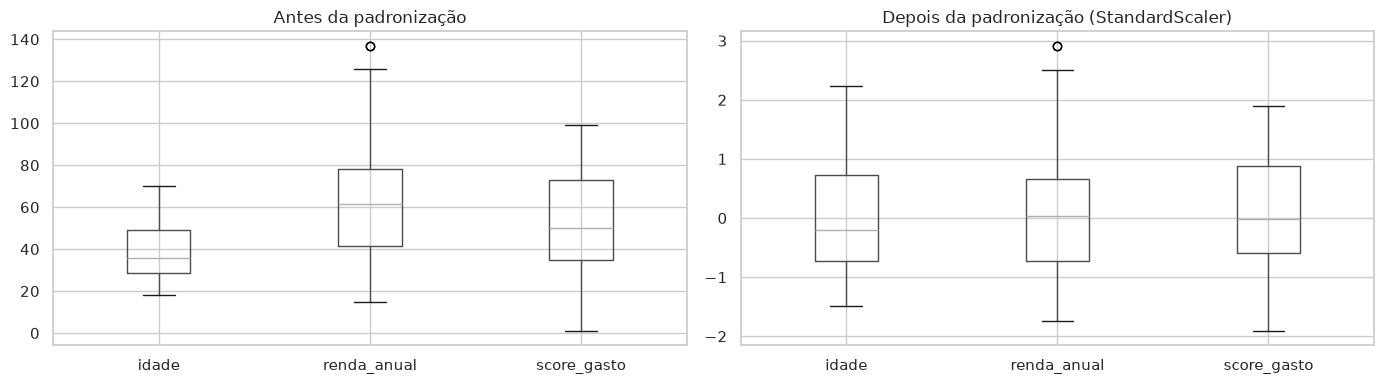

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
df[features_b].boxplot(ax=axes[0])
axes[0].set_title("Antes da padronização")
pd.DataFrame(X_b, columns=features_b).boxplot(ax=axes[1])
axes[1].set_title("Depois da padronização (StandardScaler)")
plt.tight_layout()
plt.show()

> 💡 **Insights**
> - Após a padronização, todas as variáveis têm **média 0 e desvio 1** — cada uma contribui com o mesmo peso para a distância euclidiana.
> - Sem esse passo, a renda (amplitude ~120) pesaria mais que a idade (amplitude ~50) apenas por causa da unidade de medida.
> - Os scalers foram guardados para **reverter** os centróides à escala original na interpretação.

---
# 3. Implementação do K-Means

### 3.1 Escolha do número de clusters (k)

O K-Means exige definir **k** previamente. Usaremos duas abordagens complementares, testando k de 2 a 10:

- **Método do Cotovelo (Elbow):** inércia (soma das distâncias quadráticas aos centróides). Procuramos o ponto em que o ganho de adicionar um cluster passa a ser pequeno.
- **Coeficiente de Silhueta:** mede o quão bem cada ponto se encaixa no próprio cluster vs. o cluster vizinho (−1 a 1; quanto maior, melhor).

Parâmetros do algoritmo:
- `init="k-means++"`: inicialização inteligente dos centróides, acelera a convergência e evita mínimos locais ruins;
- `n_init=10`: roda 10 inicializações e mantém a de menor inércia;
- `random_state=42`: reprodutibilidade.

In [15]:
def avaliar_k(X, ks=range(2, 11)):
    linhas = []
    for k in ks:
        km = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=RANDOM_STATE).fit(X)
        linhas.append({
            "k": k,
            "inercia": km.inertia_,
            "silhueta": silhouette_score(X, km.labels_),
            "davies_bouldin": davies_bouldin_score(X, km.labels_),
            "calinski_harabasz": calinski_harabasz_score(X, km.labels_),
        })
    return pd.DataFrame(linhas).set_index("k")


def plot_escolha_k(res, titulo, k_escolhido, nome_fig):
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
    axes[0].plot(res.index, res["inercia"], "o-")
    axes[0].axvline(k_escolhido, ls="--", c="C3", label=f"k = {k_escolhido}")
    axes[0].set(title=f"Método do Cotovelo — {titulo}", xlabel="k", ylabel="Inércia")
    axes[0].legend()
    axes[1].plot(res.index, res["silhueta"], "o-", c="C2")
    axes[1].axvline(k_escolhido, ls="--", c="C3", label=f"k = {k_escolhido}")
    axes[1].set(title=f"Silhueta média — {titulo}", xlabel="k", ylabel="Silhueta")
    axes[1].legend()
    plt.tight_layout()
    salvar(fig, nome_fig)
    plt.show()

#### Cenário A — Renda + Score

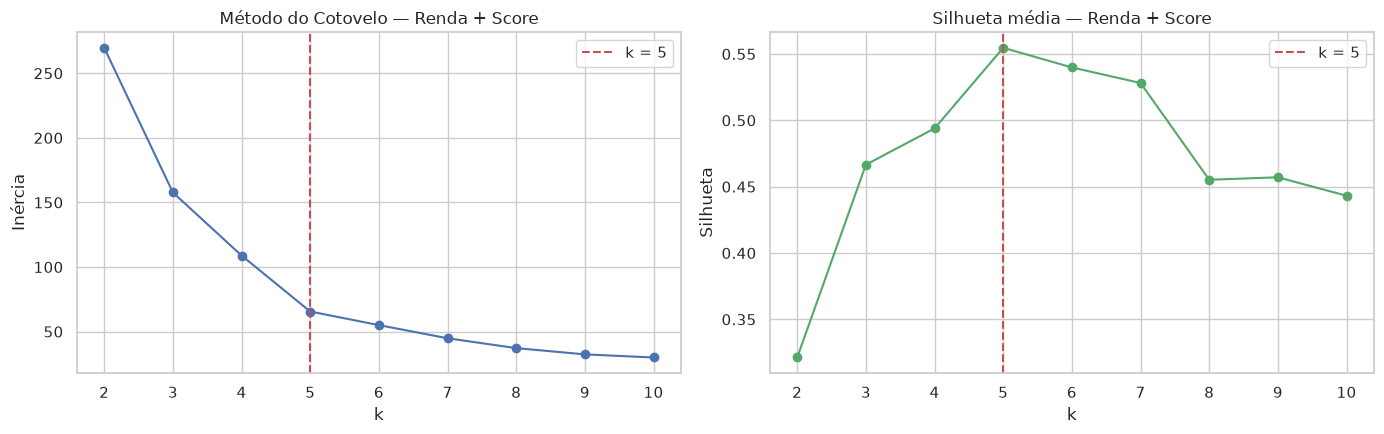

,inercia,silhueta,davies_bouldin,calinski_harabasz
k,,,,
2,269.691000,0.321000,1.267000,95.669000
3,157.704000,0.467000,0.716000,151.335000
4,108.921000,0.494000,0.710000,174.595000
5,65.568000,0.555000,0.572000,248.649000
6,55.057000,0.540000,0.655000,243.088000
7,44.865000,0.528000,0.715000,254.621000
8,37.228000,0.455000,0.760000,267.279000
9,32.392000,0.457000,0.763000,270.948000
10,29.982000,0.443000,0.793000,260.540000


In [16]:
res_a = avaliar_k(X_a)
plot_escolha_k(res_a, "Renda + Score", 5, "03_escolha_k_cenario_a")
res_a.round(3).style.highlight_max(subset=["silhueta", "calinski_harabasz"], color="#c6efce") \
    .highlight_min(subset=["davies_bouldin"], color="#c6efce")

> 💡 **Insights**
> - O cotovelo é nítido em **k = 5**: a inércia cai de ~270 (k=2) para ~66 (k=5) e, a partir daí, as quedas são pequenas.
> - A **silhueta é máxima em k = 5 (~0,55)** e o **Davies-Bouldin é mínimo (~0,57)** também em k = 5 — todas as métricas convergem.
> - Isso confirma o que o pairplot sugeria: existem **5 grupos naturais** no plano renda x score.

#### Cenário B — Idade + Renda + Score

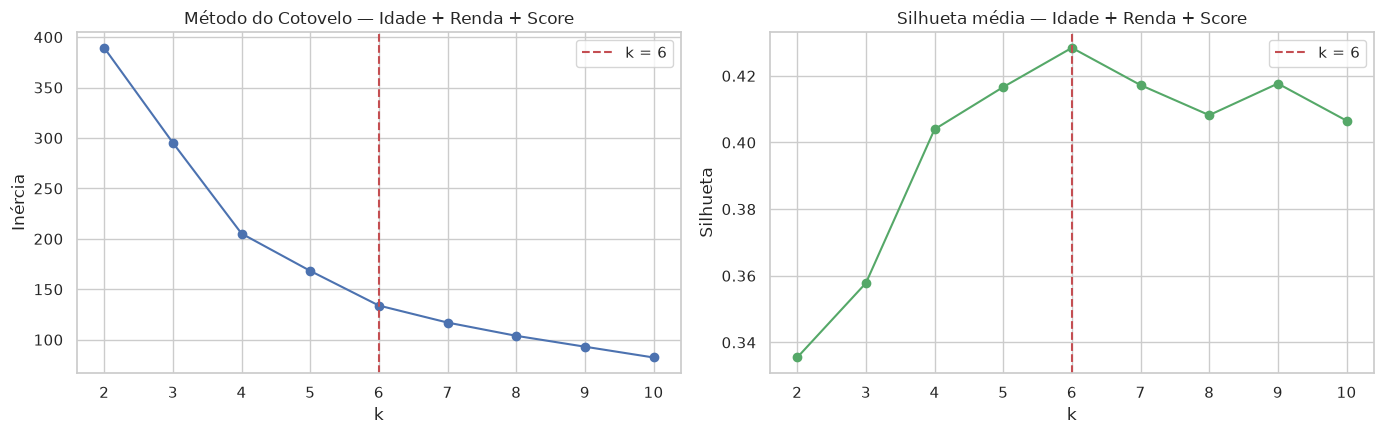

,inercia,silhueta,davies_bouldin,calinski_harabasz
k,,,,
2,389.386000,0.335000,1.261000,107.096000
3,295.212000,0.358000,1.050000,101.695000
4,205.225000,0.404000,0.931000,125.676000
5,168.248000,0.417000,0.875000,125.101000
6,133.868000,0.428000,0.825000,135.102000
7,117.012000,0.417000,0.793000,132.774000
8,103.873000,0.408000,0.892000,131.006000
9,93.093000,0.418000,0.820000,130.004000
10,82.385000,0.407000,0.868000,132.638000


In [17]:
res_b = avaliar_k(X_b)
plot_escolha_k(res_b, "Idade + Renda + Score", 6, "04_escolha_k_cenario_b")
res_b.round(3).style.highlight_max(subset=["silhueta", "calinski_harabasz"], color="#c6efce") \
    .highlight_min(subset=["davies_bouldin"], color="#c6efce")

> 💡 **Insights**
> - Com a idade, o cotovelo é **menos evidente** (curva mais suave), o que é comum ao adicionar dimensões.
> - A **silhueta atinge o máximo em k = 6 (~0,43)**, com o maior Calinski-Harabasz no mesmo ponto → escolhemos **k = 6**.
> - A silhueta do cenário B é menor que a do A (0,43 vs 0,55): os grupos ficam menos separados em 3D, mas ganham uma dimensão de interpretação (idade).

### 3.2 Treinamento dos modelos finais

In [18]:
K_A, K_B = 5, 6

kmeans_a = KMeans(n_clusters=K_A, init="k-means++", n_init=10, random_state=RANDOM_STATE).fit(X_a)
kmeans_b = KMeans(n_clusters=K_B, init="k-means++", n_init=10, random_state=RANDOM_STATE).fit(X_b)

df["cluster_a"] = kmeans_a.labels_
df["cluster_b"] = kmeans_b.labels_

# Centróides de volta à escala original
centroides_a = pd.DataFrame(scaler_a.inverse_transform(kmeans_a.cluster_centers_), columns=features_a)
centroides_b = pd.DataFrame(scaler_b.inverse_transform(kmeans_b.cluster_centers_), columns=features_b)
centroides_a.round(1)

,renda_anual,score_gasto
0,55.3,49.5
1,86.5,82.1
2,25.7,79.4
3,88.2,17.1
4,26.3,20.9


---
# 4. Avaliação e Interpretação dos Resultados

### 4.1 Métricas de qualidade

| Métrica | Interpretação | Melhor quando |
|---|---|---|
| **Silhueta** | Coesão interna vs. separação do cluster vizinho | Mais próximo de 1 |
| **Davies-Bouldin** | Razão média entre dispersão interna e distância entre clusters | Mais próximo de 0 |
| **Calinski-Harabasz** | Razão entre variância entre clusters e dentro dos clusters | Maior |

In [19]:
metricas = pd.DataFrame({
    "Cenário A (Renda+Score, k=5)": [
        silhouette_score(X_a, df["cluster_a"]),
        davies_bouldin_score(X_a, df["cluster_a"]),
        calinski_harabasz_score(X_a, df["cluster_a"]),
    ],
    "Cenário B (Idade+Renda+Score, k=6)": [
        silhouette_score(X_b, df["cluster_b"]),
        davies_bouldin_score(X_b, df["cluster_b"]),
        calinski_harabasz_score(X_b, df["cluster_b"]),
    ],
}, index=["Silhueta", "Davies-Bouldin", "Calinski-Harabasz"])
metricas.round(3)

,"Cenário A (Renda+Score, k=5)","Cenário B (Idade+Renda+Score, k=6)"
Silhueta,0.555,0.428
Davies-Bouldin,0.572,0.825
Calinski-Harabasz,248.649,135.102


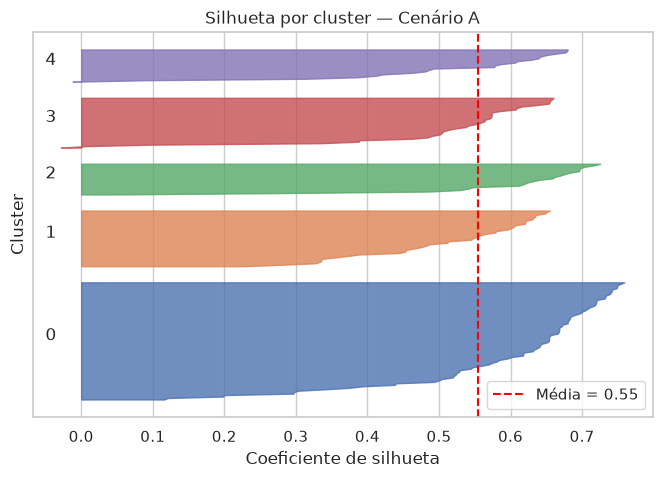

,mean,min
0,0.598,0.116
1,0.511,0.228
2,0.598,0.050
3,0.505,-0.029
4,0.511,-0.012


In [20]:
def plot_silhueta(X, labels, titulo, nome_fig):
    valores = silhouette_samples(X, labels)
    media = valores.mean()
    fig, ax = plt.subplots(figsize=(8, 5))
    y_inf = 10
    for c in np.unique(labels):
        v = np.sort(valores[labels == c])
        y_sup = y_inf + len(v)
        ax.fill_betweenx(np.arange(y_inf, y_sup), 0, v, color=f"C{c}", alpha=0.8)
        ax.text(-0.05, y_inf + len(v) / 2, str(c))
        y_inf = y_sup + 10
    ax.axvline(media, color="red", ls="--", label=f"Média = {media:.2f}")
    ax.set(title=titulo, xlabel="Coeficiente de silhueta", ylabel="Cluster", yticks=[])
    ax.legend()
    salvar(fig, nome_fig)
    plt.show()
    return pd.Series(valores).groupby(labels).agg(["mean", "min"]).round(3)


plot_silhueta(X_a, df["cluster_a"].values, "Silhueta por cluster — Cenário A", "05_silhueta_cenario_a")

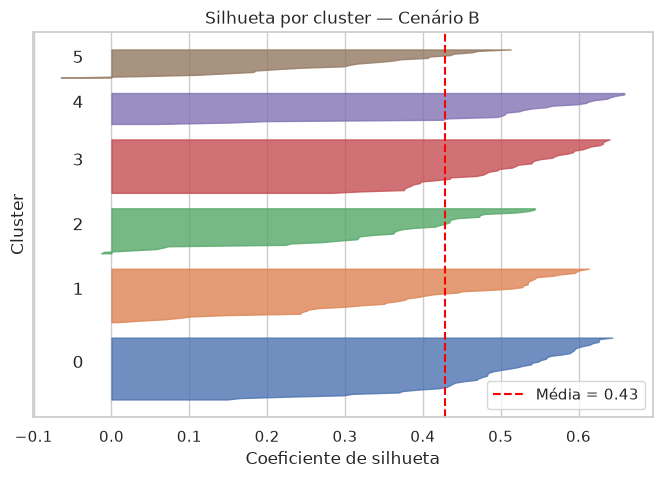

,mean,min
0,0.491,0.148
1,0.387,0.008
2,0.331,-0.013
3,0.505,0.283
4,0.508,0.056
5,0.294,-0.065


In [21]:
plot_silhueta(X_b, df["cluster_b"].values, "Silhueta por cluster — Cenário B", "06_silhueta_cenario_b")

> 💡 **Insights**
> - **Cenário A** tem as melhores métricas absolutas (silhueta ~0,55, Davies-Bouldin ~0,57): clusters **bem definidos e separados**.
> - No gráfico de silhueta, todos os clusters do cenário A ficam acima ou próximos da média e quase não há valores negativos → poucos clientes "mal alocados".
> - **Cenário B** tem métricas um pouco piores (silhueta ~0,43), mas ainda indica estrutura razoável (> 0,25). A perda de separação é o "custo" de incluir a idade.
> - Decisão: usar o **Cenário A como segmentação principal** (mais robusta e fácil de comunicar) e o **Cenário B como refinamento** por faixa de idade.

### 4.2 Visualização dos clusters — Cenário A

In [22]:
def nomear_segmento(renda, score, renda_ref, score_ref):
    """Nomeia o segmento comparando o centróide com a média geral."""
    r = "Alta renda" if renda > renda_ref * 1.2 else "Baixa renda" if renda < renda_ref * 0.8 else "Renda média"
    s = "alto gasto" if score > score_ref * 1.2 else "baixo gasto" if score < score_ref * 0.8 else "gasto moderado"
    return f"{r} / {s}"


apelidos = {
    "Alta renda / alto gasto": "VIP",
    "Alta renda / baixo gasto": "Cautelosos",
    "Baixa renda / alto gasto": "Impulsivos",
    "Baixa renda / baixo gasto": "Econômicos",
    "Renda média / gasto moderado": "Padrão",
}

renda_ref, score_ref = df["renda_anual"].mean(), df["score_gasto"].mean()
nomes_a = {
    c: nomear_segmento(row.renda_anual, row.score_gasto, renda_ref, score_ref)
    for c, row in centroides_a.iterrows()
}
nomes_a = {c: f"{apelidos.get(n, n)} ({n})" for c, n in nomes_a.items()}
df["segmento"] = df["cluster_a"].map(nomes_a)
nomes_a

{0: 'Padrão (Renda média / gasto moderado)',
 1: 'VIP (Alta renda / alto gasto)',
 2: 'Impulsivos (Baixa renda / alto gasto)',
 3: 'Cautelosos (Alta renda / baixo gasto)',
 4: 'Econômicos (Baixa renda / baixo gasto)'}

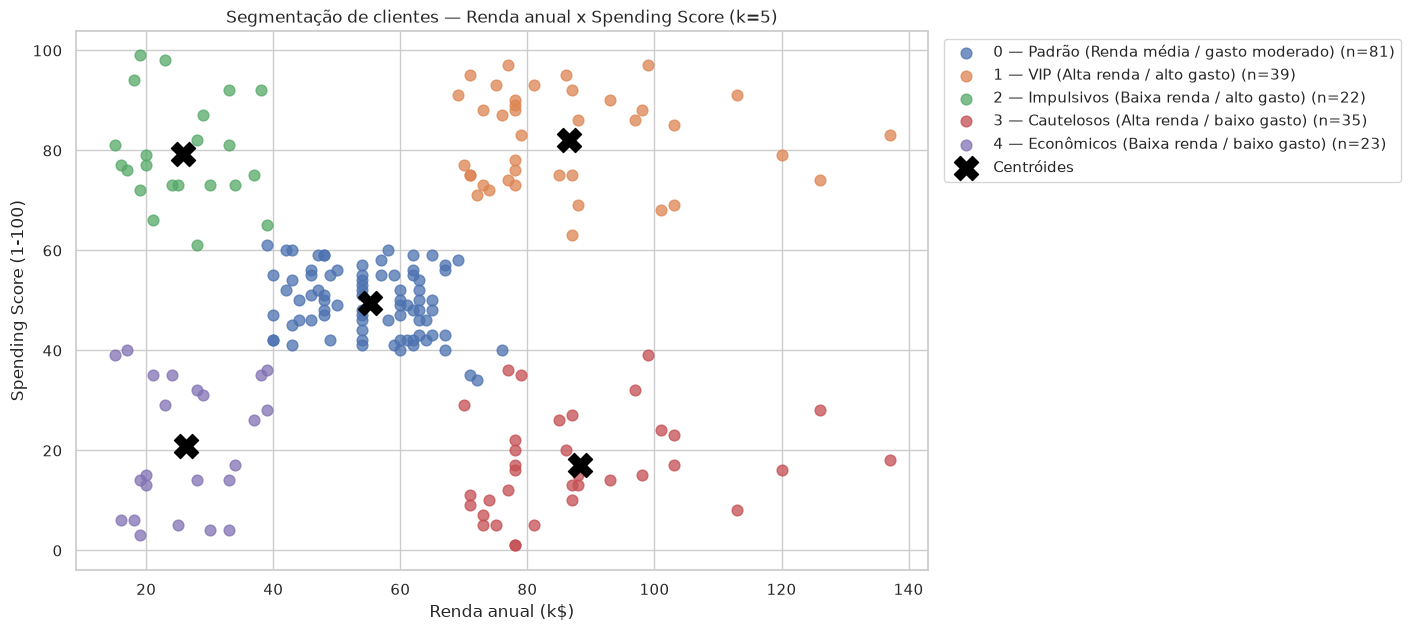

In [23]:
fig, ax = plt.subplots(figsize=(11, 7))
for c in sorted(df["cluster_a"].unique()):
    sub = df[df["cluster_a"] == c]
    ax.scatter(sub["renda_anual"], sub["score_gasto"], s=60, alpha=0.75, color=f"C{c}",
               label=f"{c} — {nomes_a[c]} (n={len(sub)})")
ax.scatter(centroides_a["renda_anual"], centroides_a["score_gasto"], s=300, c="black",
           marker="X", label="Centróides")
ax.set(title="Segmentação de clientes — Renda anual x Spending Score (k=5)",
       xlabel="Renda anual (k$)", ylabel="Spending Score (1-100)")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
salvar(fig, "07_clusters_cenario_a")
plt.show()

> 💡 **Insights**
> - Os 5 grupos ficam **visualmente bem separados**, com centróides no meio de cada "nuvem" — o modelo capturou a estrutura observada na EDA.
> - O maior grupo é o **Padrão** (renda e gasto médios, ~40% da base); os outros 4 grupos ocupam os "cantos" do gráfico.
> - Os dois grupos de alta renda (**VIP** e **Cautelosos**) têm renda parecida (~87 k$), mas comportamento oposto — a renda **sozinha não explica o gasto**.

### 4.3 Perfil dos clusters — Cenário A

In [24]:
perfil_a = df.groupby("segmento").agg(
    clientes=("id_cliente", "size"),
    idade_media=("idade", "mean"),
    renda_media=("renda_anual", "mean"),
    score_medio=("score_gasto", "mean"),
    pct_feminino=("genero", lambda s: (s == "Feminino").mean() * 100),
).round(1)
perfil_a["pct_base"] = (perfil_a["clientes"] / len(df) * 100).round(1)
perfil_a.sort_values("renda_media", ascending=False)

,clientes,idade_media,renda_media,score_medio,pct_feminino,pct_base
segmento,,,,,,
Cautelosos (Alta renda / baixo gasto),35,41.1,88.2,17.1,45.7,17.5
VIP (Alta renda / alto gasto),39,32.7,86.5,82.1,53.8,19.5
Padrão (Renda média / gasto moderado),81,42.7,55.3,49.5,59.3,40.5
Econômicos (Baixa renda / baixo gasto),23,45.2,26.3,20.9,60.9,11.5
Impulsivos (Baixa renda / alto gasto),22,25.3,25.7,79.4,59.1,11.0


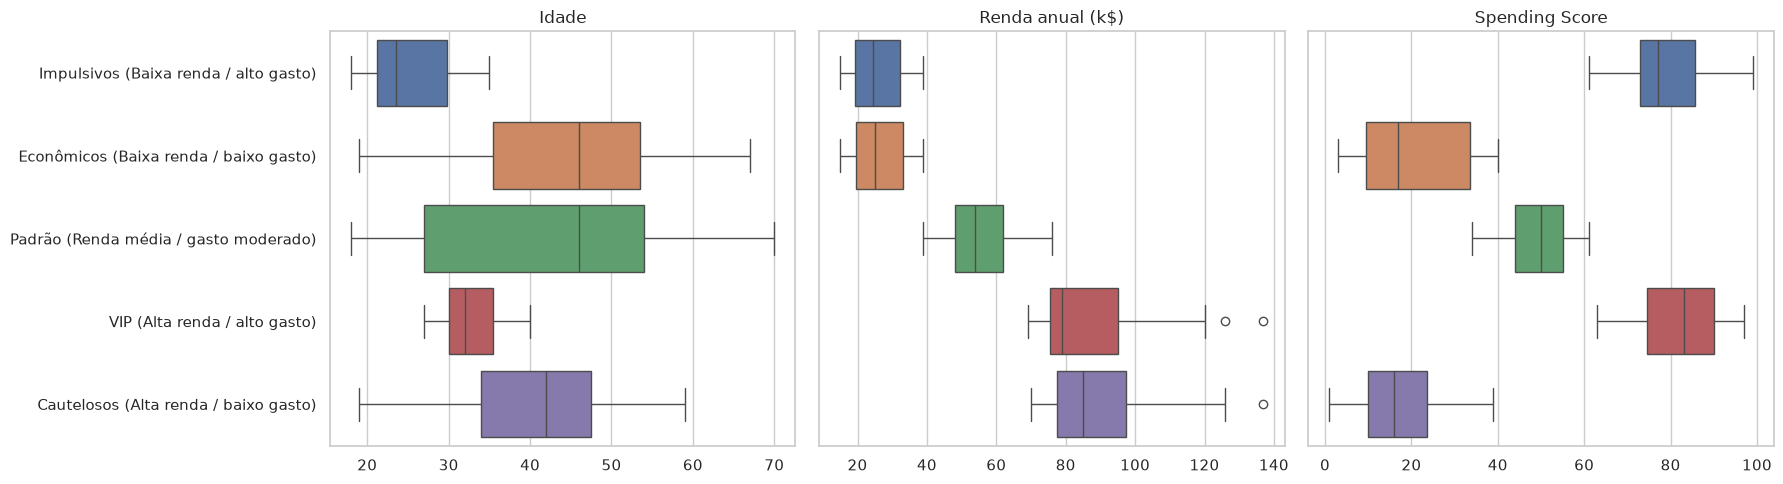

In [25]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
ordem = perfil_a.sort_values("renda_media").index
for ax, col, titulo in zip(axes, ["idade", "renda_anual", "score_gasto"],
                           ["Idade", "Renda anual (k$)", "Spending Score"]):
    sns.boxplot(data=df, y="segmento", x=col, order=ordem, ax=ax, palette="deep")
    ax.set(title=titulo, ylabel="", xlabel="")
for ax in axes[1:]:
    ax.set_yticklabels([])
plt.tight_layout()
salvar(fig, "08_perfil_segmentos")
plt.show()

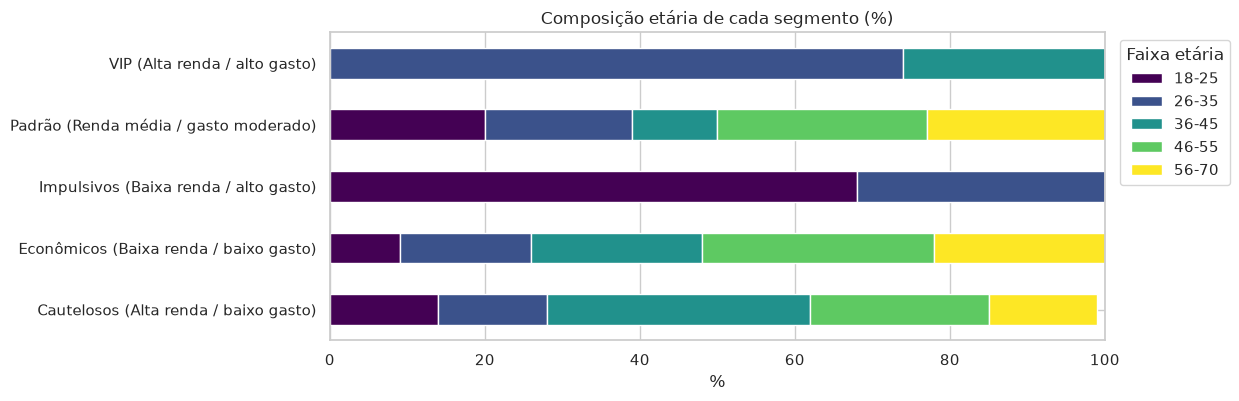

In [26]:
fig, ax = plt.subplots(figsize=(10, 4))
pd.crosstab(df["segmento"], df["faixa_etaria"], normalize="index").mul(100).round(0) \
    .plot(kind="barh", stacked=True, ax=ax, colormap="viridis")
ax.set(title="Composição etária de cada segmento (%)", xlabel="%", ylabel="")
ax.legend(title="Faixa etária", bbox_to_anchor=(1.01, 1))
plt.show()

> 💡 **Insights**
> - **VIP** (~20%): renda alta (~87 k$), score alto (~82) e **mais jovens** (média ~33 anos) — clientes mais valiosos.
> - **Cautelosos** (~17%): renda alta (~88 k$) mas score baixo (~17), idade média ~41 e o **único grupo com maioria masculina** — têm potencial de compra que não está sendo convertido.
> - **Padrão** (~40%): renda e gasto médios, faixa etária ampla (~43 anos) — o "cliente típico" do shopping.
> - **Impulsivos** (~11%): renda baixa (~26 k$) e score alto (~79), os **mais jovens** (média ~25 anos) — gastam acima do que a renda sugere.
> - **Econômicos** (~11%): renda e gasto baixos, os **mais velhos** (média ~45 anos).
> - A proporção de gênero varia pouco entre segmentos, confirmando a decisão de não usá-lo como feature.

### 4.4 Cenário B — refinamento com idade

In [27]:
renda_ref, score_ref, idade_ref = df["renda_anual"].mean(), df["score_gasto"].mean(), df["idade"].mean()


def nomear_b(row):
    base = nomear_segmento(row.renda_anual, row.score_gasto, renda_ref, score_ref)
    idade = "jovens" if row.idade < 35 else "maduros" if row.idade > 50 else "meia-idade"
    return f"{base} — {idade}"


nomes_b = {c: nomear_b(row) for c, row in centroides_b.iterrows()}
df["segmento_b"] = df["cluster_b"].map(nomes_b)

perfil_b = df.groupby("segmento_b").agg(
    clientes=("id_cliente", "size"),
    idade_media=("idade", "mean"),
    renda_media=("renda_anual", "mean"),
    score_medio=("score_gasto", "mean"),
    pct_feminino=("genero", lambda s: (s == "Feminino").mean() * 100),
).round(1).sort_values("renda_media", ascending=False)
perfil_b

,clientes,idade_media,renda_media,score_medio,pct_feminino
segmento_b,,,,,
Alta renda / baixo gasto — meia-idade,33,41.9,88.9,17.0,42.4
Alta renda / alto gasto — jovens,39,32.7,86.5,82.1,53.8
Renda média / gasto moderado — jovens,39,26.8,57.1,48.1,64.1
Renda média / gasto moderado — maduros,45,56.3,54.3,49.1,57.8
Baixa renda / baixo gasto — meia-idade,21,45.5,26.3,19.4,61.9
Baixa renda / alto gasto — jovens,23,25.0,25.3,77.6,56.5


Variância explicada pelos 2 componentes: 77.6%


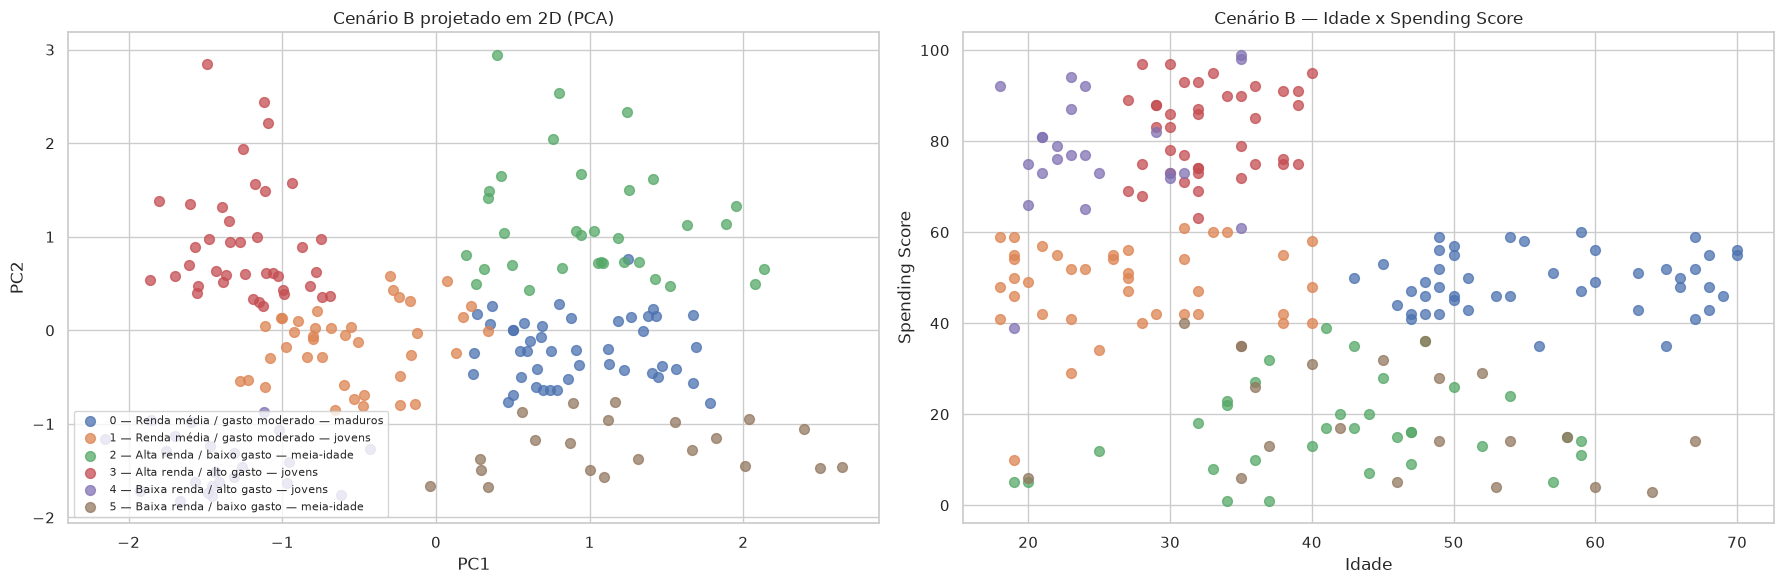

In [28]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_b_pca = pca.fit_transform(X_b)
print(f"Variância explicada pelos 2 componentes: {pca.explained_variance_ratio_.sum():.1%}")

fig, axes = plt.subplots(1, 2, figsize=(18, 6))
for c in sorted(df["cluster_b"].unique()):
    m = df["cluster_b"] == c
    axes[0].scatter(X_b_pca[m, 0], X_b_pca[m, 1], s=50, alpha=0.75, color=f"C{c}", label=f"{c} — {nomes_b[c]}")
    axes[1].scatter(df.loc[m, "idade"], df.loc[m, "score_gasto"], s=50, alpha=0.75, color=f"C{c}")
axes[0].set(title="Cenário B projetado em 2D (PCA)", xlabel="PC1", ylabel="PC2")
axes[0].legend(fontsize=8, loc="lower left")
axes[1].set(title="Cenário B — Idade x Spending Score", xlabel="Idade", ylabel="Spending Score")
plt.tight_layout()
salvar(fig, "09_clusters_cenario_b")
plt.show()

In [29]:
# Como os segmentos do Cenário A se dividem no Cenário B
pd.crosstab(df["segmento"], df["segmento_b"])

segmento_b,Alta renda / alto gasto — jovens,Alta renda / baixo gasto — meia-idade,Baixa renda / alto gasto — jovens,Baixa renda / baixo gasto — meia-idade,Renda média / gasto moderado — jovens,Renda média / gasto moderado — maduros
segmento,,,,,,
Cautelosos (Alta renda / baixo gasto),0,32,0,0,2,1
Econômicos (Baixa renda / baixo gasto),0,0,1,21,0,1
Impulsivos (Baixa renda / alto gasto),0,0,22,0,0,0
Padrão (Renda média / gasto moderado),0,1,0,0,37,43
VIP (Alta renda / alto gasto),39,0,0,0,0,0


> 💡 **Insights**
> - O Cenário B **reproduz** 4 dos 5 segmentos do Cenário A (VIP, Cautelosos, Impulsivos e Econômicos praticamente idênticos) — sinal de que a segmentação é **estável**.
> - A diferença está no grupo **Padrão**, que se divide em dois: **jovens** (~27 anos) e **maduros** (~56 anos), com renda e gasto semelhantes.
> - Esse refinamento é útil para **comunicação**: o mesmo nível de gasto pede canais e mensagens diferentes para um cliente de 27 e um de 56 anos.
> - A projeção PCA (2 componentes explicam ~78% da variância) mostra grupos razoavelmente separados, com alguma sobreposição entre os dois grupos "Padrão".

---
# 5. Aplicações Práticas

| Segmento | Perfil | Estratégia sugerida |
|---|---|---|
| **VIP** (alta renda / alto gasto) | ~20% da base, jovens (~33 anos) | Programa de fidelidade premium, acesso antecipado a lançamentos, eventos exclusivos, atendimento personalizado. **Prioridade: retenção.** |
| **Cautelosos** (alta renda / baixo gasto) | ~17% da base, ~41 anos, maioria masculina | Maior **potencial de crescimento**: entender barreiras (pesquisa), ofertas de produtos de qualidade/durabilidade, conveniência (delivery, personal shopper), comunicação racional baseada em valor. |
| **Padrão** (renda média / gasto moderado) | ~40% da base, ampla faixa etária | Campanhas de volume, cupons progressivos e *cross-selling*. Dividir comunicação por idade (Cenário B): canais digitais/redes sociais para jovens; e-mail, conforto e serviços para maduros. |
| **Impulsivos** (baixa renda / alto gasto) | ~11% da base, muito jovens (~25 anos) | Promoções relâmpago, parcelamento, marcas de *fast fashion* e entretenimento. Atenção a práticas de crédito responsáveis. |
| **Econômicos** (baixa renda / baixo gasto) | ~11% da base, ~45 anos | Ofertas de preço, liquidações, programas de cashback e produtos essenciais. Baixa prioridade de investimento em marketing. |

**Outras aplicações:**
- **Personalização de ofertas** no app/site do shopping de acordo com o segmento.
- **Mix de lojas**: a forte presença de jovens gastadores (VIP + Impulsivos ≈ 31%) justifica lojas de moda e entretenimento.
- **Alocação de orçamento de marketing** proporcional ao valor/potencial de cada segmento.
- **Classificação de novos clientes**: o modelo treinado (`kmeans_a.predict`) pode atribuir automaticamente um segmento a cada novo cadastro.

In [30]:
# Exemplo: classificar novos clientes
novos = pd.DataFrame({"renda_anual": [120, 20, 60], "score_gasto": [90, 85, 50]})
novos["segmento"] = pd.Series(kmeans_a.predict(scaler_a.transform(novos[features_a]))).map(nomes_a)
novos

,renda_anual,score_gasto,segmento
0,120,90,VIP (Alta renda / alto gasto)
1,20,85,Impulsivos (Baixa renda / alto gasto)
2,60,50,Padrão (Renda média / gasto moderado)


---
# 6. Conclusão

- A base de 200 clientes estava **limpa** (sem nulos, duplicados ou inconsistências); o tratamento consistiu em remover o identificador, não usar o gênero como feature e **padronizar** as variáveis.
- O **método do cotovelo** e as métricas de **silhueta, Davies-Bouldin e Calinski-Harabasz** convergiram para **k = 5** no cenário Renda + Score (silhueta ≈ 0,55), uma segmentação bem definida.
- Foram identificados 5 segmentos acionáveis — **VIP, Cautelosos, Padrão, Impulsivos e Econômicos** — com estratégias de marketing específicas para cada um.
- A inclusão da idade (k = 6) confirmou a estabilidade dos segmentos e refinou o grupo Padrão em jovens e maduros.
- O maior **potencial de negócio** está nos **Cautelosos** (renda alta e baixo gasto) e o maior **valor atual** nos **VIP**.

**Limitações e próximos passos**
- Dataset pequeno (200 clientes) e sem dimensão temporal (frequência, recência, ticket médio). Uma análise **RFM** com dados transacionais enriqueceria a segmentação.
- O `Spending Score` é uma métrica sintética do shopping, cuja fórmula não é conhecida.
- Testar outros algoritmos (DBSCAN, clustering hierárquico, Gaussian Mixture) e validar os segmentos com testes A/B de campanhas.